<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-04/ising-2d-monte-carlo-and-cnn.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
**Author:** Marcin Płodzień
<hr/>
# The 2D Ising model and a CNN

This notebook gathers everything the lecture shows about the Ising model in a form that runs on a laptop CPU. We first set up the model and a Metropolis sampler
implemented in JAX, using `jit` for compilation, `vmap` for many chains in parallel and `lax.scan` for the loop over sweeps. With it we generate datasets of configurations
for $L = 10, 20, 30, 40, 50$, saved to `data/ising_L{L}.npz`, and compare their magnetisation and energy with Onsager's exact results. We then draw the pictures used in the
lecture — a 1D chain, snapshots across $T_c$, the dataset — and finally train a convolutional neural network (CNN) only far from the transition, read off its confidence
at every temperature, and follow how the resulting estimate of $T_c$ depends on $L$.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"
import time, json
from functools import partial
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.special import ellipk
import jax, jax.numpy as jnp
from jax import lax
import optax
from flax import nnx

print("JAX", jax.__version__, "| devices:", jax.devices())
blue, orange, navy, grey = "#005CA7", "#D35A05", "#002B5C", "#5A6270"
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0})
mpl.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# the figures below go on the slides; they are drawn at their printed size (slide text width 5.5 in) with 11-12 pt text
SLIDE_RC = {"font.size": 12, "axes.labelsize": 12, "axes.titlesize": 12, "xtick.labelsize": 11, "ytick.labelsize": 11,
            "legend.fontsize": 11, "lines.linewidth": 1.5, "figure.dpi": 110}
OUT, DATA = "../beamer/figures", "data"
os.makedirs(OUT, exist_ok=True); os.makedirs(DATA, exist_ok=True)
NUMBERS = {}
TC = 2.0 / np.log(1.0 + np.sqrt(2.0))
print(f"Onsager: T_c = 2/ln(1+sqrt 2) = {TC:.4f}")

JAX 0.11.0 | devices: [CpuDevice(id=0)]
Onsager: T_c = 2/ln(1+sqrt 2) = 2.2692


## 1. The model and the Metropolis sampler

Spins $s_i=\pm1$ sit on an $L\times L$ lattice with periodic boundaries, $N=L^2$, with
$$
H(\mathbf s) = -J\sum_{\langle i,j\rangle} s_is_j,\qquad p(\mathbf s)=\frac{e^{-\beta H(\mathbf s)}}{Z},\qquad Z=\sum_{\mathbf s}e^{-\beta H(\mathbf s)},
$$
and $J=k_B=1$. The observables per spin are $m=\frac1N\sum_i s_i$ and $e=H/N$.

The Metropolis algorithm proposes to flip a spin $s_i$, which changes the energy by $\Delta E = 2s_i\sum_{j\in{\rm nn}(i)}s_j$, and accepts the flip with probability
$\min(1,e^{-\beta\Delta E})$. Spins of one colour of a chessboard do not interact with each other, so all of them can be updated at once; one **sweep** is the black
half followed by the white half. In JAX the sweep is a pure function, `lax.scan` repeats it, `vmap` runs many independent chains in parallel, and `jit`
compiles the whole procedure.

In [2]:
def chessboard(L):
    x, y = np.meshgrid(np.arange(L), np.arange(L), indexing="ij")
    return jnp.asarray((x + y) % 2 == 0)

def sweep(s, key, beta, black):
    for colour in (black, ~black):
        key, sub = jax.random.split(key)
        nn = jnp.roll(s, 1, 0) + jnp.roll(s, -1, 0) + jnp.roll(s, 1, 1) + jnp.roll(s, -1, 1)
        accept = jax.random.uniform(sub, s.shape) < jnp.exp(-beta * 2.0 * s * nn)
        s = jnp.where(colour & accept, -s, s)
    return s, key

@partial(jax.jit, static_argnames=("n_equil", "n_samples", "n_between"))
def sample_chains(s0, keys, Ts, black, n_equil, n_samples, n_between):
    # every chain is cooled through Ts; at each T: n_equil sweeps, then n_samples stored every n_between sweeps
    def chain(s, key):
        def at_T(carry, T):
            step = lambda c, _: (sweep(c[0], c[1], 1.0 / T, black), None)
            carry, _ = lax.scan(step, carry, None, length=n_equil)
            def store(c, _):
                c, _ = lax.scan(step, c, None, length=n_between)
                return c, c[0].astype(jnp.int8)
            return lax.scan(store, carry, None, length=n_samples)
        return lax.scan(at_T, (s, key), Ts)[1]
    return jax.vmap(chain)(s0, keys)

## 2. The datasets

For every $L$ we use 51 temperatures from 3.5 down to 1.0 (step 0.05). Forty independent chains are cooled through this grid, and at each temperature every chain
contributes 5 configurations separated by $2L$ sweeps, which gives **200 configurations per temperature**. Each file stores

* `configs`: `int8`, shape `(n_T, 200, L, L)`, values $\pm1$;
* `T`: the temperatures (ascending);
* the generation settings, so that every file documents itself.

Files already present in `data/` are loaded; the others are generated, which takes several minutes for the largest lattices.

In [3]:
L_LIST = [10, 20, 30, 40, 50]
T_GRID = np.round(np.arange(1.0, 3.5001, 0.05), 3)          # ascending, 51 values
N_CHAINS, N_SAMPLES, N_EQUIL = 40, 5, 1000

def generate(L, seed):
    k0, k1 = jax.random.split(jax.random.PRNGKey(seed))
    s0 = jnp.where(jax.random.bernoulli(k0, 0.5, (N_CHAINS, L, L)), 1.0, -1.0)
    out = sample_chains(s0, jax.random.split(k1, N_CHAINS), jnp.asarray(T_GRID[::-1], jnp.float32), chessboard(L),
                        N_EQUIL, N_SAMPLES, 2 * L)                         # (chains, nT, samples, L, L), cooling order
    out = np.asarray(out)[:, ::-1]                                           # ascending T
    return out.transpose(1, 0, 2, 3, 4).reshape(len(T_GRID), N_CHAINS * N_SAMPLES, L, L)

data = {}
for L in L_LIST:
    path = f"{DATA}/ising_L{L}.npz"
    t0 = time.time()
    if os.path.exists(path):
        f = np.load(path); data[L] = f["configs"]; how = "loaded"
    else:
        data[L] = generate(L, seed=10 + L)
        np.savez_compressed(path, configs=data[L], T=T_GRID, L=L, n_chains=N_CHAINS, n_samples_per_chain=N_SAMPLES,
                            n_equil=N_EQUIL, n_between=2 * L, sampler="checkerboard Metropolis, cooled from T=3.5")
        how = "generated"
    print(f"L = {L:2d}: {how} {data[L].shape} in {time.time() - t0:.0f} s")

L = 10: loaded (51, 200, 10, 10) in 0 s
L = 20: loaded (51, 200, 20, 20) in 0 s


L = 30: loaded (51, 200, 30, 30) in 0 s


L = 40: loaded (51, 200, 40, 40) in 0 s


L = 50: loaded (51, 200, 50, 50) in 1 s


## 3. Magnetisation and energy of finite lattices

The exact results for the infinite lattice serve as the reference. Below $T_c$ the spontaneous magnetisation is $M(T) = \left(1-\sinh^{-4}(2/T)\right)^{1/8}$ (Yang), and the
energy per spin is $u(T) = -\coth(2\beta)\left[1+\frac{2}{\pi}\left(2\tanh^2(2\beta)-1\right)K(\kappa)\right]$ with $\kappa = 2\sinh(2\beta)/\cosh^2(2\beta)$ (Onsager).
On finite lattices $\langle|m|\rangle$ stays non-zero above $T_c$ and the transition is rounded; in the figure this rounding should shrink as $L$ grows.

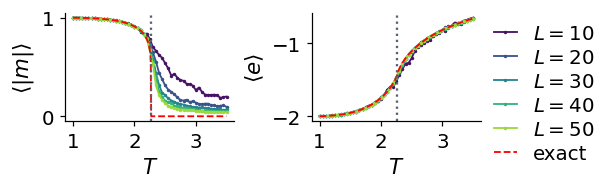

In [4]:
def M_exact(T):
    T = np.asarray(T, float); out = np.zeros_like(T); low = T < TC
    out[low] = (1 - np.sinh(2 / T[low]) ** -4) ** 0.125
    return out

def u_exact(T):
    K = 1 / np.asarray(T, float); kap = 2 * np.sinh(2 * K) / np.cosh(2 * K) ** 2
    return -1 / np.tanh(2 * K) * (1 + 2 / np.pi * (2 * np.tanh(2 * K) ** 2 - 1) * ellipk(kap ** 2))

def energy(c):
    c = c.astype(np.float32)
    return -(c * np.roll(c, 1, -1) + c * np.roll(c, 1, -2)).mean((-1, -2))

colors_L = dict(zip(L_LIST, plt.cm.viridis(np.linspace(0.05, 0.85, len(L_LIST)))))
Tf = np.linspace(1.0, 3.5, 400)
# this slide also carries two columns of text and is scaled to about 0.8 to fit, so the figure text is drawn at 13-14 pt
with plt.rc_context({**SLIDE_RC, "font.size": 14, "axes.labelsize": 14, "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 13}):
    fig, ax = plt.subplots(1, 2, figsize=(5.5, 1.6), layout="constrained")
    for L in L_LIST:
        ax[0].plot(T_GRID, np.abs(data[L].mean((-1, -2))).mean(1), ".-", ms=2.5, lw=1.2, color=colors_L[L], label=f"$L={L}$")
        ax[1].plot(T_GRID, energy(data[L]).mean(1), ".-", ms=2.5, lw=1.2, color=colors_L[L])
    ax[0].plot(Tf, M_exact(Tf), "--", color="red", lw=1.2, label="exact"); ax[1].plot(Tf, u_exact(Tf), "--", color="red", lw=1.2)
    for a, lab in zip(ax, [r"$\langle|m|\rangle$", r"$\langle e\rangle$"]):
        a.axvline(TC, color=grey, ls=":"); a.set_xlabel("$T$"); a.set_ylabel(lab); a.set_xticks([1, 2, 3])
    fig.legend(*ax[0].get_legend_handles_labels(), loc="outside right center", handlelength=1.2, labelspacing=0.25)
    fig.savefig(f"{OUT}/gen_Ising_M_E_vs_T.png", dpi=200, bbox_inches="tight", pad_inches=0.02); plt.show()

## 4. Configurations across the transition

We start with a 1D chain. With $h=0$ its bonds are independent: neighbours are parallel with probability $p=e^{\beta J}/(e^{\beta J}+e^{-\beta J})$, so chains can be
sampled exactly, bond by bond. The correlation length is $\xi=-1/\ln\tanh(\beta J)$, and the three rows below, at $T = 0.6$, $1.0$ and $5.0$, show domains whose length
shrinks with temperature. The next cell turns to two dimensions and shows $L=50$ snapshots across $T_c$, followed by a second figure with a grid of configurations from the dataset.

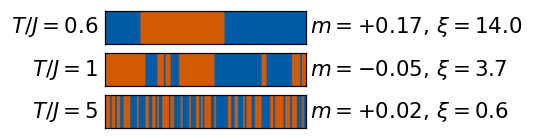

In [5]:
rng1 = np.random.default_rng(3)
# the slide with these chains is scaled to about 0.75 to fit its text, so the figure text is drawn at 14 pt
with plt.rc_context({**SLIDE_RC, "font.size": 14, "axes.labelsize": 14}):
    fig, axs = plt.subplots(3, 1, figsize=(4.73, 1.15), layout="constrained")
    for a, T in zip(axs, [0.6, 1.0, 5.0]):
        p_par = np.exp(1 / T) / (np.exp(1 / T) + np.exp(-1 / T))
        s1 = np.empty(120, int); s1[0] = 1 if rng1.random() < 0.5 else -1
        for i in range(1, 120):
            s1[i] = s1[i - 1] if rng1.random() < p_par else -s1[i - 1]
        a.imshow(s1[None, :], cmap=ListedColormap([orange, blue]), aspect="auto", vmin=-1, vmax=1)
        a.set_xticks([]); a.set_yticks([]); a.spines[:].set_visible(True); a.set_ylabel(f"$T/J={T:g}$", rotation=0, ha="right", va="center")
        a.text(1.02, 0.5, f"$m={s1.mean():+.2f}$, $\\xi={-1 / np.log(np.tanh(1 / T)):.1f}$", transform=a.transAxes, va="center")
    fig.savefig(f"{OUT}/gen_ising1d_chains.png", dpi=200, bbox_inches="tight", pad_inches=0.02); plt.show()

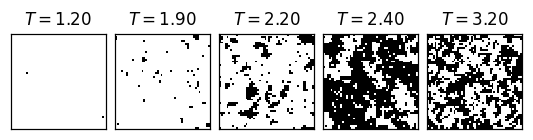

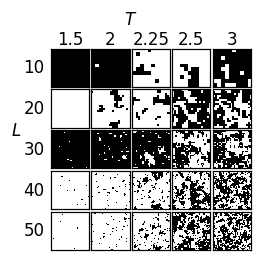

In [6]:
T_row = [1.2, 1.9, 2.2, 2.4, 3.2]
with plt.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 5, figsize=(4.73, 1.2), layout="constrained")
    for a, Tv in zip(axs, T_row):
        i = int(np.argmin(abs(T_GRID - Tv)))
        a.imshow(data[50][i, 0], cmap="gray", vmin=-1, vmax=1, interpolation="nearest"); a.set_xticks([]); a.set_yticks([]); a.spines[:].set_visible(True)
        a.set_title(f"$T = {T_GRID[i]:.2f}$", fontsize=11)
    fig.savefig(f"{OUT}/gen_Ising_configs_L50_row.png", dpi=200, bbox_inches="tight", pad_inches=0.02); plt.show()

T_show = [1.5, 2.0, 2.25, 2.5, 3.0]
with plt.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(len(L_LIST), len(T_show), figsize=(2.2, 2.2), layout="constrained")
    fig.get_layout_engine().set(w_pad=0.01, h_pad=0.01, wspace=0.02, hspace=0.02)
    for r, L in enumerate(L_LIST):
        for k, Tv in enumerate(T_show):
            i = int(np.argmin(abs(T_GRID - Tv))); a = axs[r, k]
            a.imshow(data[L][i, 0], cmap="gray", vmin=-1, vmax=1, interpolation="nearest"); a.set_xticks([]); a.set_yticks([]); a.spines[:].set_visible(True)
            if r == 0: a.set_title(f"{T_GRID[i]:g}", fontsize=11, pad=2)
            if k == 0: a.set_ylabel(f"{L}", fontsize=11, rotation=0, ha="right", va="center")
    fig.suptitle("$T$", fontsize=11); fig.supylabel("$L$", fontsize=11, rotation=0)
    fig.savefig(f"{OUT}/gen_Ising_dataset.png", dpi=200, bbox_inches="tight", pad_inches=0.02); plt.show()

## 5. The critical temperature from CNN confidence

The network is trained only where the answer is clear: configurations with $T<1.5$ get the label 0 (ordered), those with $T>3$ the label 1
(disordered), and nothing between 1.5 and 3 is used for training.

The network, built with Flax NNX, consists of two blocks of a $3\times3$ convolution with 16 channels (with periodic boundaries, like the lattice), ReLU and
$2\times2$ max pooling, followed by global average pooling, a dense layer of 32 ReLU units and 2 outputs with softmax; it is trained with the cross-entropy loss and Adam.
Global average pooling makes the same network work for every $L$.

After training we predict at every temperature. For one configuration the network gives $p_1$, the probability of "disordered", and its **confidence** is
$\max(p_0,p_1)$. This yields two estimates of $T_c$: the temperature where the average confidence is lowest, and the temperature where $\langle p_1\rangle_T$
crosses $1/2$. Each lattice size is trained with three seeds, and the printout gives the mean and spread of both estimates.

In [7]:
class IsingCNN(nnx.Module):
    def __init__(self, *, rngs):
        self.c1 = nnx.Conv(1, 16, (3, 3), padding="CIRCULAR", rngs=rngs)
        self.c2 = nnx.Conv(16, 16, (3, 3), padding="CIRCULAR", rngs=rngs)
        self.d1 = nnx.Linear(16, 32, rngs=rngs); self.d2 = nnx.Linear(32, 2, rngs=rngs)
    def __call__(self, x):
        h = x[..., None]
        h = nnx.max_pool(nnx.relu(self.c1(h)), (2, 2), strides=(2, 2))
        h = nnx.max_pool(nnx.relu(self.c2(h)), (2, 2), strides=(2, 2))
        h = h.mean(axis=(1, 2))                                  # global average pooling
        return self.d2(nnx.relu(self.d1(h)))                     # logits

@nnx.jit
def train_step(model, opt, x, y):
    def loss_fn(m):
        return optax.softmax_cross_entropy_with_integer_labels(m(x), y).mean()
    loss, grads = nnx.value_and_grad(loss_fn)(model)
    opt.update(model, grads)
    return loss

@nnx.jit
def prob_disordered(model, x):
    return jax.nn.softmax(model(x))[:, 1]

T_MIN, T_MAX = 1.5, 3.0
def train_cnn(L, seed, epochs=8, batch=64):
    c = data[L]
    low, high = T_GRID < T_MIN, T_GRID > T_MAX
    X = np.concatenate([c[low].reshape(-1, L, L), c[high].reshape(-1, L, L)]).astype(np.float32)
    y = np.concatenate([np.zeros(c[low].shape[0] * c.shape[1], int), np.ones(c[high].shape[0] * c.shape[1], int)])
    model = IsingCNN(rngs=nnx.Rngs(seed)); opt = nnx.Optimizer(model, optax.adam(1e-3), wrt=nnx.Param)
    X, y = jnp.asarray(X), jnp.asarray(y); key = jax.random.PRNGKey(seed)
    for ep in range(epochs):
        key, k = jax.random.split(key); perm = jax.random.permutation(k, len(y))
        for i in range(0, len(y) - batch + 1, batch):
            train_step(model, opt, X[perm[i:i + batch]], y[perm[i:i + batch]])
    acc = float(((prob_disordered(model, X) > 0.5) == y).mean())
    return model, acc

def predict_all(model, L):
    c = jnp.asarray(data[L].reshape(-1, L, L), jnp.float32)
    return np.asarray(prob_disordered(model, c)).reshape(len(T_GRID), -1)

def estimates(p1):
    conf = np.maximum(p1, 1 - p1).mean(1); p1m = p1.mean(1)
    i = int(np.argmin(conf)); T_conf = T_GRID[i]
    j = int(np.where(np.diff(np.sign(p1m - 0.5)) != 0)[0][0])
    T_cross = T_GRID[j] + (0.5 - p1m[j]) * (T_GRID[j + 1] - T_GRID[j]) / (p1m[j + 1] - p1m[j])
    return conf, p1m, T_conf, T_cross

SEEDS = [0, 1, 2]
results = {}
t0 = time.time()
for L in L_LIST:
    runs = []
    for seed in SEEDS:
        model, acc = train_cnn(L, seed)
        runs.append((acc,) + estimates(predict_all(model, L)))
    results[L] = runs
    Tc_conf = np.array([r[3] for r in runs]); Tc_cross = np.array([r[4] for r in runs])
    print(f"L = {L:2d}: training accuracy {np.mean([r[0] for r in runs]):.4f}; T_c from the confidence minimum "
          f"{Tc_conf.mean():.3f} +- {Tc_conf.std():.3f}; from <p1> = 1/2: {Tc_cross.mean():.3f} +- {Tc_cross.std():.3f}"
          f"   ({time.time() - t0:.0f} s)")

L = 10: training accuracy 0.9998; T_c from the confidence minimum 2.267 +- 0.103; from <p1> = 1/2: 2.281 +- 0.030   (17 s)


L = 20: training accuracy 1.0000; T_c from the confidence minimum 2.283 +- 0.024; from <p1> = 1/2: 2.286 +- 0.030   (30 s)


L = 30: training accuracy 1.0000; T_c from the confidence minimum 2.283 +- 0.024; from <p1> = 1/2: 2.293 +- 0.018   (55 s)


L = 40: training accuracy 1.0000; T_c from the confidence minimum 2.283 +- 0.024; from <p1> = 1/2: 2.285 +- 0.027   (96 s)


L = 50: training accuracy 1.0000; T_c from the confidence minimum 2.283 +- 0.024; from <p1> = 1/2: 2.285 +- 0.031   (157 s)


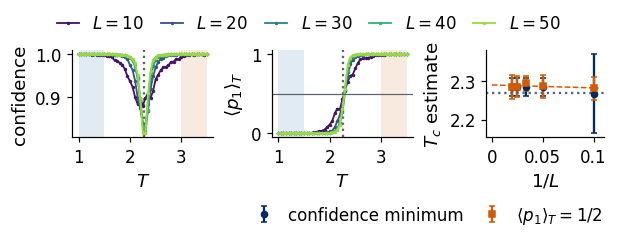

<p1> = 1/2 crossing extrapolated to L -> infinity (linear in 1/L): 2.290   (exact 2.2692)


In [8]:
invL = 1 / np.array(L_LIST)
tc_conf = np.array([np.mean([r[3] for r in results[L]]) for L in L_LIST]); tc_conf_e = np.array([np.std([r[3] for r in results[L]]) for L in L_LIST])
tc_cross = np.array([np.mean([r[4] for r in results[L]]) for L in L_LIST]); tc_cross_e = np.array([np.std([r[4] for r in results[L]]) for L in L_LIST])
fit = np.polyfit(invL, tc_cross, 1); xx = np.linspace(0, invL.max() * 1.05, 50)
with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(1, 3, figsize=(5.5, 2.15), layout="constrained", gridspec_kw=dict(width_ratios=[1.2, 1.2, 1]))
    for a in ax[:2]:
        a.axvspan(T_GRID.min(), T_MIN, color=blue, alpha=0.12, lw=0); a.axvspan(T_MAX, T_GRID.max(), color=orange, alpha=0.12, lw=0)
        a.axvline(TC, color=grey, ls=":"); a.set_xlabel("$T$"); a.set_xticks([1, 2, 3])
    lines = []
    for L in L_LIST:
        conf = np.mean([r[1] for r in results[L]], axis=0); p1m = np.mean([r[2] for r in results[L]], axis=0)
        lines += ax[0].plot(T_GRID, conf, ".-", ms=2.5, lw=1.2, color=colors_L[L], label=f"$L={L}$")
        ax[1].plot(T_GRID, p1m, ".-", ms=2.5, lw=1.2, color=colors_L[L])
    ax[0].set_ylabel("confidence")
    ax[1].axhline(0.5, color=grey, lw=0.8); ax[1].set_ylabel(r"$\langle p_1\rangle_T$")
    e1 = ax[2].errorbar(invL, tc_conf, tc_conf_e, fmt="o", ms=4, color=navy, capsize=2, label="confidence minimum")
    e2 = ax[2].errorbar(invL, tc_cross, tc_cross_e, fmt="s", ms=4, color=orange, capsize=2, label=r"$\langle p_1\rangle_T = 1/2$")
    ax[2].plot(xx, np.polyval(fit, xx), "--", color=orange, lw=1)
    ax[2].axhline(TC, color=grey, ls=":"); ax[2].set_xlabel("$1/L$"); ax[2].set_ylabel("$T_c$ estimate")
    ax[2].set_xticks([0, 0.05, 0.1], ["0", "0.05", "0.1"])
    fig.legend(lines, [x.get_label() for x in lines], loc="outside upper center", ncol=5, handlelength=1.3, columnspacing=1.0)
    fig.legend([e1, e2], [e1.get_label(), e2.get_label()], loc="outside lower right", ncol=2, handlelength=1.3, columnspacing=1.0)
    fig.savefig(f"{OUT}/gen_Ising_confidence_vs_T_L.png", dpi=200, bbox_inches="tight", pad_inches=0.02); plt.show()
print(f"<p1> = 1/2 crossing extrapolated to L -> infinity (linear in 1/L): {fit[1]:.3f}   (exact {TC:.4f})")
NUMBERS.update(tc_conf={str(L): [round(float(a), 3), round(float(b), 3)] for L, a, b in zip(L_LIST, tc_conf, tc_conf_e)},
               tc_cross={str(L): [round(float(a), 3), round(float(b), 3)] for L, a, b in zip(L_LIST, tc_cross, tc_cross_e)},
               tc_cross_extrap=round(float(fit[1]), 3))

The estimates lie between $2.267$ and $2.293$ for all sizes, and the linear extrapolation of the crossing in $1/L$ gives $2.290$, against the exact $2.2692$.
The final figure, used on the slide, shows a single size, $L=50$ with seed 0, with the confidence of every configuration coloured by the predicted phase; its minimum lies at $T=2.25$.

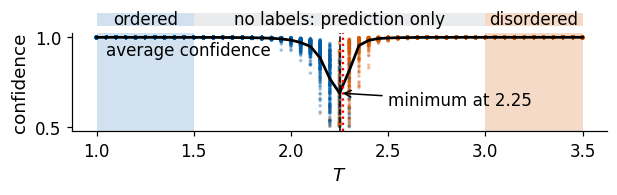

In [9]:
L = 50
model, _ = train_cnn(L, seed=0)
p1 = predict_all(model, L); conf_all = np.maximum(p1, 1 - p1)
conf, p1m, T_conf, T_cross = estimates(p1)
with plt.rc_context(SLIDE_RC):
    fig, (axb, ax) = plt.subplots(2, 1, figsize=(5.5, 1.6), sharex=True, layout="constrained", gridspec_kw=dict(height_ratios=[0.4, 3]))
    fig.get_layout_engine().set(h_pad=0.01, hspace=0.0)
    for a in (axb, ax):
        a.axvspan(T_GRID.min(), T_MIN, color=blue, alpha=0.18, lw=0); a.axvspan(T_MAX, T_GRID.max(), color=orange, alpha=0.22, lw=0)
    axb.axvspan(T_MIN, T_MAX, color=grey, alpha=0.12, lw=0)
    axb.text(1.25, 0.5, "ordered", ha="center", va="center", fontsize=11)
    axb.text(2.25, 0.5, "no labels: prediction only", ha="center", va="center", fontsize=11)
    axb.text(3.25, 0.5, "disordered", ha="center", va="center", fontsize=11); axb.axis("off")
    TT = np.repeat(T_GRID, conf_all.shape[1])
    ax.scatter(TT, conf_all.ravel(), s=2, c=np.where(p1.ravel() > 0.5, orange, blue), alpha=0.25, rasterized=True)
    ax.plot(T_GRID, conf, "k-", lw=1.8)
    ax.axvline(T_conf, color="k", ls="--", lw=1); ax.axvline(TC, color="red", ls=":", lw=1.5)
    ax.annotate(f"minimum at {T_conf:.2f}", xy=(T_conf, conf.min()), xytext=(2.5, 0.62), fontsize=11,
                arrowprops=dict(arrowstyle="->", color="k", lw=1))
    ax.text(1.05, 0.9, "average confidence", fontsize=11); ax.set_xlabel("$T$"); ax.set_ylabel("confidence")
    fig.savefig(f"{OUT}/gen_Ising_confidence_vs_T.png", dpi=200, bbox_inches="tight", pad_inches=0.02); plt.show()
NUMBERS.update(slide_L=L, slide_T_conf=round(float(T_conf), 3), slide_T_cross=round(float(T_cross), 3))

### Exercises
1. Train with the windows $T<2.0$ and $T>2.6$, closer to $T_c$. Does the estimate improve, and does it depend less on $L$?
2. Replace the global average pooling by flattening. Why does the network then work only for the $L$ it was trained on?
3. Use the network trained on $L=20$ to predict on $L=50$ configurations. What happens to the confidence curve?

### References
* L. Onsager, Phys. Rev. **65**, 117 (1944), [doi:10.1103/PhysRev.65.117](https://doi.org/10.1103/PhysRev.65.117); C. N. Yang, Phys. Rev. **85**, 808 (1952), [doi:10.1103/PhysRev.85.808](https://doi.org/10.1103/PhysRev.85.808)
* J. Carrasquilla, R. G. Melko, *Machine learning phases of matter*, Nature Physics (2017), [arXiv:1605.01735](https://arxiv.org/abs/1605.01735)
* M. E. J. Newman, G. T. Barkema, *Monte Carlo Methods in Statistical Physics*, Oxford University Press (1999)